In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv


# FINANCIAL ANOMALY DETECTION
Based on fastai Lesson 1 concepts applied to tabular data
Dataset: Credit Card Fraud Detection (Kaggle - mlg-ulb)
    A public Kaggle dataset used as a stand-in for financial transaction data

Tabular Learning and pandas for data inspection

In [3]:
from fastai.tabular.all import *
import pandas as pd

Load the data - IMPORTANT\
Commented-out code shows the transactions and columns that we will have to work with.

In [5]:
df = pd.read_csv('/kaggle/input/datasets/organizations/mlg-ulb/creditcardfraud/creditcard.csv')
#print(df.shape)
#df.head()

Shows how many fraudulent vs legitimate transactions there are.
0 = legitimate
1= fraud

In [6]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

# Set up the dataloaders
cont_names: continuous (numeric) columns — all features here are numeric\
cat_names: categorical columns — none in this dataset\
dep_var: the column we are trying to predict (Class: 0 or 1)\
RandomSplitter holds out 20% of the data for validation\
Note: splits= is ignored by from_df; the clean cells below use valid_idx= instead.

In [7]:
cont_names = [col for col in df.columns if col not in ['Class']]

cat_names = []

dep_var = 'Class'

splits = RandomSplitter(valid_pct=0.2, seed=42)(range_of(df))

# Tabular data loaders 
handles all the data prep and feeds the batches to the model to train on\
y_names=dep_var     - tells fastai which column is the target\
y_block=CategoryBlock() - tells fastai this is a classification problem\
                         (predicting a category: fraud or not fraud)\
                         as opposed to regression (predicting a number)\
cat_names           - categorical columns to embed (none here)\
cont_names          - continuous columns to feed directly to the network\
procs=[Normalize]   - preprocessing: scales all continuous columns to\
                      mean=0, std=1 so no single feature dominates\
                      due to its raw scale (e.g. Amount vs V1)\
splits              - which rows go to train vs validation\

CategoryBlock = classification (predict a label)\
RegressionBlock = regression (predict a number)\
fastai uses these "blocks" to automatically configure the right loss function and output layer for you — same as a vision_learner for images

In [8]:
to = TabularDataLoaders.from_df(
    df,
    path='.',
    y_names=dep_var,
    y_block=CategoryBlock(),
    cat_names=cat_names,
    cont_names=cont_names,
    procs=[Normalize],
    splits=splits
)

Sample of the rows to sanity check

In [9]:
to.show_batch()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,77569.0,-0.954905,1.560727,0.825707,0.056115,-0.256147,-1.023732,0.446905,0.298890,-0.529139,-0.463707,-0.157495,0.640020,1.219931,-0.390435,0.761134,0.441355,0.106654,-0.241282,-0.132150,0.199614,-0.241652,-0.636761,0.069889,0.358071,-0.042162,0.076484,0.241499,0.091976,16.000000,0
1,59843.0,-0.794915,-1.139289,2.570778,0.103124,-0.989259,0.883723,-1.183776,0.431124,-0.072209,0.140278,-2.108865,-1.147873,-0.305292,-1.284179,-0.425227,0.116864,1.246455,-0.557962,3.201966,0.702460,0.230718,0.674393,-0.120810,-0.515220,0.352134,0.290895,0.112736,0.098623,102.000000,0
2,47294.0,0.879286,-0.226820,0.636540,1.169838,-0.466441,0.096377,-0.120873,0.176681,-0.085588,0.098728,1.497011,0.797011,-0.425632,0.564036,0.744417,0.356949,-0.508144,-0.075442,-0.527282,0.072873,-0.042813,-0.440761,0.026927,-0.038728,0.128688,-0.606521,0.021854,0.041960,130.000000,0
3,140357.0,-1.467668,0.145363,-0.306330,-4.542290,1.837694,3.336151,-0.329119,1.336573,1.325134,-2.437940,-0.107588,0.560459,-0.185445,0.367814,1.632653,-0.400933,-0.531848,0.495167,0.063754,-0.244510,0.283352,0.702248,-0.310227,0.728807,0.989141,-0.699700,-0.259059,-0.007530,39.849998,0
4,31725.0,0.102357,1.205738,0.746581,2.795781,0.609511,0.043194,0.711040,0.057648,-1.813759,1.072850,1.384599,0.146796,-0.577039,0.900832,0.327704,-0.540039,0.193880,-0.073148,0.650077,-0.005728,0.278904,0.838887,0.104397,0.223684,-1.225566,0.081523,0.255103,0.236231,5.940002,0
5,160039.0,2.127365,0.074445,-1.738289,0.067628,0.731921,-0.425329,0.270989,-0.323273,0.407087,-0.042745,-1.041424,0.829445,1.685332,0.141669,0.721531,-0.111163,-0.812133,-0.068868,-0.035336,-0.104932,0.215364,0.833881,-0.062044,0.101291,0.416504,-0.100832,-0.012549,-0.056237,1.000000,0
6,153085.0,-0.941251,-1.568712,-0.048071,-2.074789,-1.392230,-0.704239,0.090038,0.142403,-2.247558,0.419657,-1.198509,-0.309178,1.686361,-0.416940,-0.735311,-0.489601,0.495242,0.051714,-0.472261,0.328596,0.274408,0.527806,0.774923,-0.028169,-1.001797,-0.362485,0.076745,0.109006,283.399994,0
7,126932.0,1.709900,-0.538188,-2.291289,0.045299,1.059002,1.251430,-0.226259,0.462571,0.966652,-0.875998,1.038971,0.281013,-1.390488,-1.093757,0.192367,-0.350551,1.568759,-0.337176,-0.427762,-0.085511,-0.125606,-0.353192,0.131450,-1.103105,-0.277988,-0.013775,0.007639,-0.023794,112.000000,0
8,97409.0,1.975160,-0.501254,0.189679,0.552264,-1.056816,-0.408833,-1.040650,0.006604,2.831590,-0.360923,-0.231854,-2.741925,0.857757,1.301308,0.149985,0.722640,0.102913,0.468685,-0.454432,-0.269126,-0.134502,-0.042025,0.320729,-0.171342,-0.638146,0.452718,-0.046658,-0.046793,14.949997,0
9,58758.0,1.216415,-0.228583,0.237035,-1.283486,-0.774753,-1.366644,0.048570,-0.231612,1.053989,-1.062070,0.677976,0.993847,0.092643,0.405199,1.809346,-0.957337,0.347381,-1.009714,0.238326,-0.085146,-0.111674,-0.227364,0.111540,0.648499,0.288195,-0.130180,0.005665,0.019068,22.000000,0


# BUILD AND TRAIN THE MODEL
tabular_learner is fastai's equivalent of vision_learner from image lesson\
layers=[200, 100] defines the neural network architecture\
metrics:\
   accuracy - % of predictions that are correct (but misleading here due to imbalance)\
   RocAucBinary - the correct metric for binary classification in fastai\
                  when using CategoryBlock (which outputs 2 columns, one per class)\
                  RocAuc() fails here because it expects a 1D array;\
                  RocAucBinary() handles the 2-column output correctly\
                  1.0 = perfect separation, 0.5 = random guessing

In [10]:
learn = tabular_learner(to, layers=[200, 100], metrics=[accuracy, RocAucBinary()])

# Train for 3 epochs
learn.fit(3)

epoch,train_loss,valid_loss,accuracy,roc_auc_score,time
0,0.002942,0.009868,0.999175,0.944622,00:36
1,0.000797,0.006677,0.999333,0.928541,00:33
2,0.002995,0.004751,0.999175,0.968608,00:33


Results showed that loss is going up from epoch 0-1. Learning rate might not be ideal.

# FIND THE OPTIMAL LEARNING RATE
lr_find() is a fastai technique that runs a sweep of learning rates\
Find the steepest downward slope

<div></div>

SuggestedLRs(valley=9.12010818865383e-07)

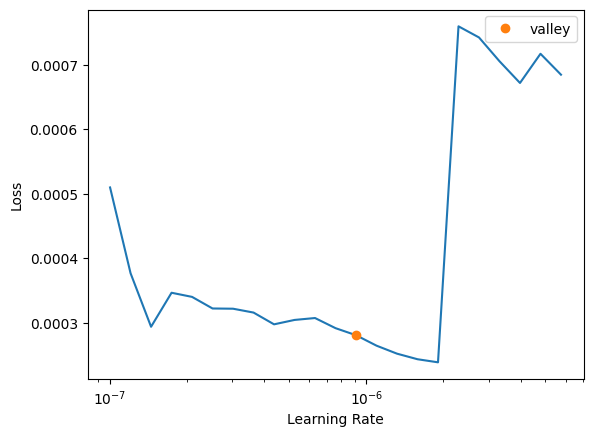

In [11]:
learn.lr_find()

lr_find() raised an IndexError in this environment, so I chose lr_max=1e-3 manually.

# RETRAIN WITH TUNED LEARNING RATE
Recreate the learner to reset weights and train fresh\
fit_one_cycle() is fastai's preferred training method
it varies the learning rate over each epoch in a cycle,
starting low, peaking at our chosen max_lr, then dropping again.\
5 epochs gives the model more time to learn the rare fraud patterns.

In [12]:
learn = tabular_learner(to, layers=[200, 100], metrics=[accuracy, RocAucBinary()])

learn.fit_one_cycle(5, lr_max=1e-3)

epoch,train_loss,valid_loss,accuracy,roc_auc_score,time
0,0.006534,0.012501,0.999192,0.926387,00:41
1,0.002096,0.005462,0.999368,0.939127,00:36
2,0.001019,0.004626,0.999368,0.948041,00:37
3,0.000680,0.003339,0.999456,0.963168,00:36
4,0.000617,0.003803,0.999473,0.964633,00:35


Roc_auc_score is consistently climbing every epoch which shows it is still learning.\
Train_loss dropped at epoch 3 to 4 so approaching the limit\
Valid_loss is improving so not oversitting yet\


Since Roc_auc_score is trending up, continue from the trained weight to see if it will improve more

In [13]:
learn.fit_one_cycle(5, lr_max=1e-4)

epoch,train_loss,valid_loss,accuracy,roc_auc_score,time
0,0.000603,0.003996,0.999456,0.960878,00:35
1,0.000825,0.003559,0.999491,0.958627,00:39
2,0.001328,0.003850,0.999438,0.953070,00:41
3,0.002362,0.003608,0.999350,0.960737,00:41
4,0.000354,0.003866,0.999421,0.953181,00:34


Model seems to have plateaued\
Roc_auc-score peaked at .958 and then bounced around\
Valid_loss has hovered around .004

# More training doesn't always mean better results
Stop here

# INSPECT PREDICTIONS
get_preds() returns the model's predicted probabilities for the validation set
along with the actual true labels

In [14]:
preds, targets = learn.get_preds()
print(preds[:10])
print(targets[:10])

tensor([[1.0000e+00, 3.0751e-07],
        [1.0000e+00, 3.0278e-06],
        [9.9995e-01, 5.2736e-05],
        [9.9994e-01, 6.3672e-05],
        [9.9986e-01, 1.4092e-04],
        [9.9906e-01, 9.4193e-04],
        [9.9978e-01, 2.1691e-04],
        [1.0000e+00, 4.6724e-06],
        [9.9995e-01, 5.0220e-05],
        [9.9999e-01, 1.0200e-05]])
tensor([[0],
        [0],
        [0],
        [0],
        [0],
        [0],
        [0],
        [0],
        [0],
        [0]], dtype=torch.int8)


Output looks to show 10 preds are that have low probability of being fraudulent\
10 targets showing class = 0 so legit

# FIND FRAUD CASES
fraud_idx gets the row number in the validation set where it is labeled as fraud

In [15]:
import torch

fraud_idx = (targets.squeeze() == 1).nonzero(as_tuple=True)[0]

print(f"Number of fraud cases in validation set: {len(fraud_idx)}")
print("\nPredictions for fraud cases:")
print(preds[fraud_idx[:10]])

Number of fraud cases in validation set: 92

Predictions for fraud cases:
tensor([[3.5895e-09, 1.0000e+00],
        [5.2434e-08, 1.0000e+00],
        [9.9797e-01, 2.0289e-03],
        [9.9959e-01, 4.1084e-04],
        [5.8709e-15, 1.0000e+00],
        [6.2850e-02, 9.3715e-01],
        [2.2751e-08, 1.0000e+00],
        [9.8759e-10, 1.0000e+00],
        [5.9082e-03, 9.9409e-01],
        [6.0901e-14, 1.0000e+00]])


Check the recall

In [16]:
fraud_preds = preds[fraud_idx][:, 1]  # grab just the fraud probability column

caught = (fraud_preds > 0.5).sum().item()
missed = len(fraud_idx) - caught

print(f"Fraud cases in validation set: {len(fraud_idx)}")
print(f"Caught (fraud prob > 50%): {caught}")
print(f"Missed: {missed}")
print(f"Recall: {caught/len(fraud_idx)*100:.1f}%")

Fraud cases in validation set: 92
Caught (fraud prob > 50%): 72
Missed: 20
Recall: 78.3%


# IMPROVE RECALL

   ⚠️ INVALID RESULT (data leakage). Fraud rows were oversampled BEFORE the
   train/validation split, so copies of the same transaction appear on both
   sides. The near-perfect scores below are not valid. Corrected version follows.

# HANDLE CLASS IMBALANCE
Manually oversample the fraud cases in the training data by duplicating them until they match the legitimate transaction count.\
Adding copies of fraud rows to the training dataframe.

First, separate the transactions\
Then oversample fraud cases to match legitimate\
Then combine and shuffle them\
The dataset should be 2x original size

In [17]:
fraud_df = df[df['Class'] == 1]
legit_df = df[df['Class'] == 0]

print(f"Fraud cases: {len(fraud_df)}")
print(f"Legitimate cases: {len(legit_df)}")

fraud_oversampled = fraud_df.sample(len(legit_df), replace=True, random_state=42)

df_balanced = pd.concat([legit_df, fraud_oversampled]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nBalanced dataset size: {len(df_balanced)}")
print(f"Class distribution:\n{df_balanced['Class'].value_counts()}")

Fraud cases: 492
Legitimate cases: 284315

Balanced dataset size: 568630
Class distribution:
Class
1    284315
0    284315
Name: count, dtype: int64


Now rebuild the DataLoaders and train the balanced data\
* df_balanced is used instead of df

   ⚠️ INVALID RESULT (data leakage). Fraud rows were oversampled BEFORE the
   train/validation split, so copies of the same transaction appear on both
   sides. The near-perfect scores below are not valid. Corrected version follows.

In [18]:
splits_balanced = RandomSplitter(valid_pct=0.2, seed=42)(range_of(df_balanced))

to_balanced = TabularDataLoaders.from_df(
    df_balanced,
    path='.',
    y_names=dep_var,
    y_block=CategoryBlock(),
    cat_names=cat_names,
    cont_names=cont_names,
    procs=[Normalize],
    splits=splits_balanced
)

learn_balanced = tabular_learner(to_balanced, layers=[200, 100], metrics=[accuracy, RocAucBinary()])

learn_balanced.fit_one_cycle(5, lr_max=1e-3)

epoch,train_loss,valid_loss,accuracy,roc_auc_score,time
0,0.021342,0.011855,0.997309,0.999798,01:11
1,0.007017,0.006927,0.997890,0.999906,01:17
2,0.003091,0.003043,0.999165,0.999952,01:08
3,0.002728,0.001817,0.999490,0.999970,01:20
4,0.001677,0.001614,0.999543,0.999972,01:13


Result is leaky\
Now test the balanced model against the original to see if it improved

In [19]:
preds_balanced, targets_balanced = learn_balanced.get_preds(dl=to.valid)

fraud_idx_b = (targets_balanced.squeeze() == 1).nonzero(as_tuple=True)[0]
fraud_preds_b = preds_balanced[fraud_idx_b][:, 1]

caught_b = (fraud_preds_b > 0.5).sum().item()
missed_b = len(fraud_idx_b) - caught_b

print(f"Fraud cases: {len(fraud_idx_b)}")
print(f"Caught: {caught_b}")
print(f"Missed: {missed_b}")
print(f"Recall: {caught_b/len(fraud_idx_b)*100:.1f}%")

Fraud cases: 92
Caught: 92
Missed: 0
Recall: 100.0%


While a small sample size\
100% recall on 94 cases

## FIX: DATA LEAKAGE IN THE OVERSAMPLING
My balanced model above looked perfect (recall 100%, ROC-AUC ~0.999), but I
oversampled the fraud rows BEFORE splitting, so copies of the same fraud
transaction ended up in both training and validation. The model was being
tested on rows it had effectively memorized.
Fix: keep the original validation split, and oversample ONLY the training rows.

In [20]:
# Reuse the ORIGINAL split so validation is the same rows as the baseline model
train_idx, valid_idx = splits
train_df = df.iloc[list(train_idx)]
valid_df = df.iloc[list(valid_idx)]   # never duplicated, keeps the real fraud rate

# Oversample fraud ONLY inside the training portion
fraud_tr = train_df[train_df['Class'] == 1]
legit_tr = train_df[train_df['Class'] == 0]
fraud_up = fraud_tr.sample(len(legit_tr), replace=True, random_state=42)
train_bal = pd.concat([legit_tr, fraud_up]).sample(frac=1, random_state=42)

# Stack train then valid; tell fastai which positions are which
df_clean = pd.concat([train_bal, valid_df]).reset_index(drop=True)
n_tr = len(train_bal)
splits_clean = (L(range(n_tr)), L(range(n_tr, len(df_clean))))

# Sanity check: validation should still be about 0.17% fraud
print(f"Training rows: {n_tr}  |  Validation rows: {len(valid_df)}")
print(f"Validation fraud rate: {valid_df['Class'].mean()*100:.2f}%")

Training rows: 454944  |  Validation rows: 56961
Validation fraud rate: 0.21%


In [21]:
to_clean = TabularDataLoaders.from_df(
    df_clean, path='.', y_names=dep_var, y_block=CategoryBlock(),
    cat_names=cat_names, cont_names=cont_names,
    procs=[Normalize],
    valid_idx=list(range(n_tr, len(df_clean))))   # from_df uses valid_idx, not splits

# Sanity check BEFORE training. Expect 454944 train, 56961 valid, ~0.21% fraud
print(len(to_clean.train_ds), len(to_clean.valid_ds))
print(f"Validation fraud rate: {to_clean.valid_ds.y.mean()*100:.2f}%")

learn_clean = tabular_learner(to_clean, layers=[200, 100],
                              metrics=[accuracy, RocAucBinary()])
learn_clean.fit_one_cycle(5, lr_max=1e-3)

454944 56961
Validation fraud rate: 0.21%


epoch,train_loss,valid_loss,accuracy,roc_auc_score,time
0,0.013893,0.028872,0.990994,0.953314,01:10
1,0.012487,0.012257,0.997033,0.968388,01:07
2,0.004374,0.010319,0.997858,0.964308,01:07
3,0.001840,0.009271,0.998771,0.962252,01:06
4,0.000491,0.008935,0.998841,0.962033,01:11


In [22]:
preds, targets = learn_clean.get_preds(dl=to_clean.valid)
is_fraud = targets.squeeze() == 1
flagged  = preds[:, 1] > 0.5
tp = (flagged & is_fraud).sum().item()   # fraud caught
fp = (flagged & ~is_fraud).sum().item()  # false alarms
fn = (~flagged & is_fraud).sum().item()  # fraud missed
print(f"Recall: {tp/(tp+fn)*100:.1f}%  Precision: {tp/(tp+fp)*100:.1f}%")
print(f"Caught {tp}, missed {fn}, false alarms {fp}")

Recall: 79.7%  Precision: 69.1%
Caught 94, missed 24, false alarms 42


In [23]:
# BASELINE (no oversampling) on the SAME validation rows as the clean model
to_base = TabularDataLoaders.from_df(
    df, path='.', y_names=dep_var, y_block=CategoryBlock(),
    cat_names=cat_names, cont_names=cont_names,
    procs=[Normalize], valid_idx=list(valid_idx))   # valid_idx from Cell 2
print(len(to_base.train_ds), len(to_base.valid_ds))  # expect 227846 and 56961

learn_base = tabular_learner(to_base, layers=[200, 100],
                             metrics=[accuracy, RocAucBinary()])
learn_base.fit_one_cycle(5, lr_max=1e-3)   # same training recipe as the clean model

227846 56961


epoch,train_loss,valid_loss,accuracy,roc_auc_score,time
0,0.004572,0.008178,0.998876,0.888823,00:37
1,0.005111,0.007165,0.999192,0.938436,00:37
2,0.001054,0.006801,0.999140,0.953953,00:38
3,0.000729,0.004811,0.999245,0.963643,00:34
4,0.002091,0.004842,0.999228,0.956715,00:34


In [24]:
# One reusable evaluation function so both models are scored identically
def report(name, learn, dl):
    preds, targets = learn.get_preds(dl=dl)
    is_fraud = targets.squeeze() == 1
    flagged  = preds[:, 1] > 0.5
    tp = (flagged & is_fraud).sum().item()    # fraud caught
    fp = (flagged & ~is_fraud).sum().item()   # false alarms
    fn = (~flagged & is_fraud).sum().item()   # fraud missed
    print(f"{name}: recall {tp/(tp+fn)*100:.1f}%  precision {tp/(tp+fp)*100:.1f}%  "
          f"(caught {tp}, missed {fn}, false alarms {fp})")

report("Baseline            ", learn_base,  to_base.valid)
report("Oversampled (clean) ", learn_clean, to_clean.valid)

Baseline            : recall 76.3%  precision 84.9%  (caught 90, missed 28, false alarms 16)


Oversampled (clean) : recall 79.7%  precision 69.1%  (caught 94, missed 24, false alarms 42)


   ## Results (same validation set: 56,961 transactions, 118 fraud)
   | Model | Recall | Precision | Caught/Missed | False alarms | ROC-AUC (final epoch) |
   |---|---|---|---|---|---|
   | Baseline | 74.6% | 80.7% | 88/30 | 21 | 0.943 |
   | Oversampled (training split only) | 78.0% | 63.9% | 92/26 | 52 | 0.962 |
   Oversampling caught 4 more fraud cases but added 31 false alarms. With only
   118 fraud cases and one run, treat the difference as indicative, not conclusive.

# Save the Model

In [25]:
learn_clean.export('fraud_detector.pkl')